# DIR300 — khám phá dữ liệu

**Mục tiêu:** hiểu bộ ảnh đang có trên máy, kiểm tra input–reference, khảo sát kích thước,
màu sắc, độ sáng và độ tương phản trước khi chạy classical CV / deep learning.

**Cấu trúc bạn đang dùng:** `data/DIR300/dist/1.png` và `data/DIR300/gt/1.png`.
`dist` là ảnh biến dạng; `gt` là ảnh phẳng tham chiếu. Ghép theo ID số giống nhau,
không ghép theo thứ tự danh sách file. Phần mở rộng được xử lý không phân biệt hoa/thường
để nhận cả file như `248.PNG`.

**Mốc kiểm tra:** benchmark gồm 300 cặp ảnh. Nếu bản đang tải chưa đủ 300 input và
300 reference, notebook vẫn khảo sát phần hiện có và chỉ rõ ID/cặp bị thiếu.
Reference ảnh phẳng không đồng nghĩa với ground truth lưới hình học hay OCR transcript.

Thông tin nền: [DocScanner — repository tác giả và mục DIR300](https://github.com/fh2019ustc/DocScanner).
Các kết quả EDA được tính từ file thực tế, không mặc định rằng tải về đã đầy đủ.


## 1. Chuẩn bị và cấu hình

Đặt notebook trong `notebooks/`, mở bằng VS Code/Jupyter và chạy từ trên xuống.
Cài dependency một lần ở terminal tại repo: `python -m pip install -r requirements-eda.txt`.
Chọn đúng Python kernel đã cài các thư viện. Không cần GPU, không tải thêm dữ liệu tự động.

Thống kê W/H và dung lượng lấy từ file gốc; W/H hiển thị đã áp dụng EXIF orientation.
Màu/ánh sáng được ước lượng trên thumbnail cạnh dài tối đa 512 px để chạy nhẹ.
File gốc không bị sửa. Điều chỉnh `ANALYSIS_MAX_SIDE` nếu muốn so sánh độ ổn định thống kê.


In [1]:
DATASET_NAME = 'DIR300'
INPUT_FOLDER = 'dist'
REFERENCE_FOLDER = 'gt'
EXPECTED_COUNTS = {'input': 300, 'reference': 300}
EXPECTED_DOCUMENTS = 300


from pathlib import Path
from collections import defaultdict
import re
import warnings
import math
import json
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
from IPython.display import display

pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False,
                     'font.size': 10})
COLORS = {'input': '#477998', 'reference': '#8C9A73'}
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp', '.webp'}
SEED = 42
SAMPLE_COUNT = 6
ANALYSIS_MAX_SIDE = 512  # Chỉ thống kê màu/ánh sáng trên thumbnail.
EXPORT = True          # CSV, metadata và hình được lưu ở reports/eda/.

# None: tự tìm từ thư mục notebook hoặc thư mục gốc repo.
# Nếu cần, sửa thành Path(r'D:\HCMUT\HK261\CV\ImageProcessing_and_ComputerVision_CC01').
PROJECT_ROOT = None
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / 'data' / DATASET_NAME).is_dir()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            f'Không tìm thấy data/{DATASET_NAME}. Đặt notebook trong notebooks/ của repo '
            'hoặc sửa PROJECT_ROOT bằng đường dẫn repo trên máy bạn.')
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
DATASET_ROOT = PROJECT_ROOT / 'data' / DATASET_NAME
INPUT_DIR = DATASET_ROOT / INPUT_FOLDER
REFERENCE_DIR = DATASET_ROOT / REFERENCE_FOLDER
OUTPUT_DIR = PROJECT_ROOT / 'reports' / 'eda' / DATASET_NAME.lower()
if ANALYSIS_MAX_SIDE < 16:
    raise ValueError('ANALYSIS_MAX_SIDE cần >= 16.')
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Dataset:', DATASET_ROOT)
print('Input:', INPUT_DIR)
print('Reference:', REFERENCE_DIR)
print('Output:', OUTPUT_DIR)
print('Python:', platform.python_version(), '| Pillow:', PIL.__version__)


Dataset: D:\HCMUT\HK261\CV\ImageProcessing_and_ComputerVision_CC01\data\DIR300
Input: D:\HCMUT\HK261\CV\ImageProcessing_and_ComputerVision_CC01\data\DIR300\dist
Reference: D:\HCMUT\HK261\CV\ImageProcessing_and_ComputerVision_CC01\data\DIR300\gt
Output: D:\HCMUT\HK261\CV\ImageProcessing_and_ComputerVision_CC01\reports\eda\dir300
Python: 3.10.20 | Pillow: 12.2.0


## 2. Cấu trúc và số lượng file

Đếm input và reference riêng; hiển thị thư mục thực tế, extension, ID và view.
Số lượng kỳ vọng là mốc kiểm tra độ đầy đủ, không phải điều kiện bắt buộc để chạy EDA.


In [2]:
def image_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f'Chưa có thư mục {folder}. Kiểm tra giải nén hoặc INPUT_FOLDER/REFERENCE_FOLDER.')
    # Đệ quy để hỗ trợ crop/crop, scan/scan; bỏ file metadata của macOS.
    return sorted((p for p in folder.rglob('*')
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
                   and not p.name.startswith('._') and '__MACOSX' not in p.parts),
                  key=lambda p: p.relative_to(folder).as_posix().casefold())

def parse_identity(path, role):
    stem = path.stem.strip()
    if DATASET_NAME == 'DocUNet' and role == 'input':
        match = re.fullmatch(r'(\d+)_(\d+)(?:\s+copy(?:\s*\(\d+\))?)?', stem, re.I)
        if match:
            return str(int(match[1])), str(int(match[2]))
    else:
        match = re.fullmatch(r'\d+', stem)
        if match:
            return str(int(stem)), ''
    return None, None

records = []
for role, folder in [('input', INPUT_DIR), ('reference', REFERENCE_DIR)]:
    for path in image_files(folder):
        document_id, view_id = parse_identity(path, role)
        records.append({'role': role, 'path': str(path),
                        'relative_path': path.relative_to(PROJECT_ROOT).as_posix(),
                        'filename': path.name, 'extension': path.suffix.lower(),
                        'document_id': document_id, 'view_id': view_id})
inventory = pd.DataFrame(records, columns=['role', 'path', 'relative_path', 'filename',
                                          'extension', 'document_id', 'view_id'])
counts = inventory['role'].value_counts()
count_table = pd.DataFrame([
    {'role': role, 'expected_images': expected, 'found_images': int(counts.get(role, 0)),
     'difference': int(counts.get(role, 0)) - expected}
    for role, expected in EXPECTED_COUNTS.items()
])
display(count_table)
if any(count_table['difference'] != 0):
    warnings.warn('Số lượng chưa khớp benchmark. Có thể tải chưa xong, thiếu ảnh hoặc giải nén trùng; xem audit bên dưới.')
print('Các thư mục thực sự chứa ảnh:')
display(inventory.assign(parent=inventory['relative_path'].map(lambda p: str(Path(p).parent)))
        .groupby(['role', 'parent'], dropna=False).size().rename('images').reset_index())
display(inventory.head(12).drop(columns='path'))
if inventory.empty:
    raise RuntimeError('Chưa tìm thấy ảnh. Hoàn tất giải nén dữ liệu rồi chạy lại.')


,role,expected_images,found_images,difference
0,input,300,148,-152
1,reference,300,150,-150


Các thư mục thực sự chứa ảnh:


C:\Users\ACER\AppData\Local\Temp\ipykernel_15272\4156776257.py:40: UserWarning: Số lượng chưa khớp benchmark. Có thể tải chưa xong, thiếu ảnh hoặc giải nén trùng; xem audit bên dưới.
  warnings.warn('Số lượng chưa khớp benchmark. Có thể tải chưa xong, thiếu ảnh hoặc giải nén trùng; xem audit bên dưới.')


,role,parent,images
0,input,data\DIR300\dist,148
1,reference,data\DIR300\gt,150


,role,relative_path,filename,extension,document_id,view_id
0,input,data/DIR300/dist/1.png,1.png,.png,1,
1,input,data/DIR300/dist/10.png,10.png,.png,10,
2,input,data/DIR300/dist/100.png,100.png,.png,100,
3,input,data/DIR300/dist/102.png,102.png,.png,102,
4,input,data/DIR300/dist/103.png,103.png,.png,103,
5,input,data/DIR300/dist/106.png,106.png,.png,106,
6,input,data/DIR300/dist/107.png,107.png,.png,107,
7,input,data/DIR300/dist/11.png,11.png,.png,11,
8,input,data/DIR300/dist/110.png,110.png,.png,110,
9,input,data/DIR300/dist/112.png,112.png,.png,112,


## 3. Kiểm tra ghép cặp và ID

Phát hiện tên lạ, ID trùng, input thiếu reference, reference thiếu input và các ID thiếu.
Không tự chọn một reference khi nhiều file cùng ID, vì có thể làm sai phép so sánh.
Ghép đúng tên vẫn cần xem ảnh cạnh nhau để xác nhận nội dung.


In [3]:
inputs = inventory[inventory['role'].eq('input')].copy()
references = inventory[inventory['role'].eq('reference')].copy()
bad_names = inventory[inventory['document_id'].isna()].copy()
valid_names = inventory[inventory['document_id'].notna()].copy()
duplicate_names = valid_names[valid_names.duplicated(['role', 'document_id', 'view_id'], keep=False)]

reference_index = defaultdict(list)
for row in references.to_dict('records'):
    if row['document_id'] is not None:
        reference_index[row['document_id']].append(row)

pair_records = []
input_key_counts = inputs.groupby(['document_id', 'view_id']).size().to_dict()
for row in inputs.to_dict('records'):
    doc_id, view_id = row['document_id'], row['view_id']
    candidates = reference_index.get(doc_id, []) if doc_id is not None else []
    if doc_id is None:
        status = 'unrecognized_input_name'
    elif input_key_counts.get((doc_id, view_id), 0) > 1:
        status = 'duplicate_input_id'
    elif not candidates:
        status = 'missing_reference'
    elif len(candidates) > 1:
        status = 'ambiguous_reference'
    else:
        status = 'matched_by_id'
    pair_records.append({'document_id': doc_id, 'view_id': view_id,
                         'input_path': row['path'], 'input_relative_path': row['relative_path'],
                         'reference_path': candidates[0]['path'] if status == 'matched_by_id' else None,
                         'reference_relative_path': candidates[0]['relative_path'] if status == 'matched_by_id' else None,
                         'pair_status': status})
pairs = pd.DataFrame(pair_records, columns=['document_id', 'view_id', 'input_path', 'input_relative_path',
                                          'reference_path', 'reference_relative_path', 'pair_status'])
used_doc_ids = set(inputs['document_id'].dropna())
unreferenced = references[references['document_id'].notna() & ~references['document_id'].isin(used_doc_ids)]
print('Ghép theo ID tên file; chưa xác nhận ảnh có đọc được hay không:')
display(pairs['pair_status'].value_counts().rename_axis('status').reset_index(name='inputs'))
for label, frame in [('Tên chưa nhận dạng', bad_names), ('ID ảnh bị trùng', duplicate_names),
                     ('Reference chưa có input cùng ID', unreferenced)]:
    print(f'{label}: {len(frame)}')
    if len(frame):
        display(frame[['role', 'relative_path', 'document_id', 'view_id']].head(20))
if len(pairs):
    display(pairs.loc[~pairs['pair_status'].eq('matched_by_id'),
                      ['input_relative_path', 'pair_status']].head(30))
    print('Số view theo từng document ID (giúp phát hiện thiếu view của DocUNet):')
    view_counts = inputs.dropna(subset=['document_id']).groupby('document_id')['view_id'].nunique()
    display(view_counts.value_counts().sort_index().rename_axis('views_per_document').reset_index(name='documents'))

expected_ids = {str(i) for i in range(1, EXPECTED_DOCUMENTS + 1)}
for role in ['input', 'reference']:
    actual_ids = set(inventory.loc[inventory['role'].eq(role), 'document_id'].dropna())
    print(role, '| missing document IDs:', sorted(expected_ids - actual_ids, key=int))
    print(role, '| unexpected document IDs:', sorted(actual_ids - expected_ids, key=int))
if DATASET_NAME == 'DocUNet':
    expected_views = {(str(i), str(v)) for i in range(1, 66) for v in (1, 2)}
    actual_views = set(zip(inputs['document_id'].dropna(), inputs.loc[inputs['document_id'].notna(), 'view_id']))
    print('Missing (document, view):', sorted(expected_views - actual_views, key=lambda v: (int(v[0]), int(v[1]))))
    print('Unexpected (document, view):', sorted(actual_views - expected_views, key=lambda v: (int(v[0]), int(v[1]))))


Ghép theo ID tên file; chưa xác nhận ảnh có đọc được hay không:


,status,inputs
0,matched_by_id,83
1,missing_reference,65


Tên chưa nhận dạng: 0
ID ảnh bị trùng: 0
Reference chưa có input cùng ID: 67


,role,relative_path,document_id,view_id
150,reference,data/DIR300/gt/105.png,105,
153,reference,data/DIR300/gt/108.png,108,
154,reference,data/DIR300/gt/109.png,109,
159,reference,data/DIR300/gt/116.png,116,
163,reference,data/DIR300/gt/125.png,125,
164,reference,data/DIR300/gt/126.png,126,
167,reference,data/DIR300/gt/138.png,138,
168,reference,data/DIR300/gt/139.png,139,
169,reference,data/DIR300/gt/14.png,14,
173,reference,data/DIR300/gt/144.png,144,


,input_relative_path,pair_status
1,data/DIR300/dist/10.png,missing_reference
2,data/DIR300/dist/100.png,missing_reference
4,data/DIR300/dist/103.png,missing_reference
7,data/DIR300/dist/11.png,missing_reference
9,data/DIR300/dist/112.png,missing_reference
13,data/DIR300/dist/12.png,missing_reference
15,data/DIR300/dist/121.png,missing_reference
16,data/DIR300/dist/122.png,missing_reference
19,data/DIR300/dist/128.png,missing_reference
21,data/DIR300/dist/135.png,missing_reference


Số view theo từng document ID (giúp phát hiện thiếu view của DocUNet):


,views_per_document,documents
0,1,148


input | missing document IDs: ['3', '4', '8', '13', '14', '15', '17', '19', '20', '23', '24', '26', '27', '28', '29', '31', '34', '38', '39', '41', '42', '44', '48', '49', '50', '51', '52', '53', '54', '57', '58', '59', '63', '65', '67', '68', '69', '72', '73', '75', '78', '79', '80', '83', '84', '86', '88', '89', '91', '92', '93', '95', '96', '97', '101', '104', '105', '108', '109', '111', '116', '117', '118', '119', '125', '126', '127', '130', '131', '132', '133', '134', '138', '139', '144', '145', '152', '155', '157', '158', '159', '161', '162', '163', '165', '167', '169', '170', '171', '175', '177', '180', '181', '182', '183', '184', '186', '190', '191', '198', '200', '202', '204', '205', '207', '208', '209', '212', '213', '215', '217', '218', '219', '221', '223', '226', '227', '231', '233', '235', '236', '238', '241', '242', '244', '245', '246', '248', '253', '255', '257', '262', '265', '266', '268', '269', '271', '273', '274', '275', '277', '280', '283', '284', '285', '288', '289

## 4. Đọc ảnh và đo đặc trưng

Quét từng ảnh, không giữ toàn bộ dataset trong RAM. File không đọc được có bảng lỗi riêng.
`original_mode`/số kênh ghi từ file gốc; phép đo màu và hiển thị dùng RGB, alpha trên nền trắng.

| Nhóm | Định nghĩa |
|---|---|
| Kích thước | Width, height, W/H, W×H, megapixels, dung lượng MiB |
| Độ sáng | Trung bình grayscale Pillow `L` / 255, trong [0,1] |
| Tương phản | Độ lệch chuẩn grayscale; thêm P95 − P05 để bớt nhạy với cực trị |
| Màu | Trung bình R/G/B và HSV saturation, trong [0,1] |
| Phân bố sáng | Tỷ lệ grayscale < 0.05 và > 0.95; entropy histogram grayscale (bit) |

Đây là mô tả ảnh, **không phải** điểm chất lượng unwarping. Nền giấy trắng, chữ, hình màu,
biên nền và bóng đổ đều ảnh hưởng số đo. Không tự kết luận ảnh sáng nhất là tốt nhất.
RGB/grayscale là cường độ mã hóa, không phải phép đo độ chói vật lý đã hiệu chuẩn.


In [4]:
def rgb_image(image):
    # Dùng cùng quy tắc cho thống kê và hiển thị: EXIF transpose, alpha đặt trên nền trắng.
    image = ImageOps.exif_transpose(image)
    if 'A' in image.getbands() or 'transparency' in image.info:
        rgba = image.convert('RGBA')
        background = Image.new('RGBA', rgba.size, (255, 255, 255, 255))
        return Image.alpha_composite(background, rgba).convert('RGB')
    return image.convert('RGB')

def load_thumbnail(path, max_side=ANALYSIS_MAX_SIDE):
    with Image.open(path) as image:
        rgb = rgb_image(image)
        rgb.thumbnail((max_side, max_side), Image.Resampling.LANCZOS)
        return rgb.copy()

def analyze_file(record):
    result = dict(record)
    result.update({'read_ok': False, 'error': '', 'file_bytes': np.nan})
    try:
        path = Path(record['path'])
        result['file_bytes'] = path.stat().st_size
        with Image.open(path) as image:
            raw_width, raw_height = image.size
            result.update({'raw_width': raw_width, 'raw_height': raw_height,
                           'original_mode': image.mode, 'image_format': image.format,
                           'original_channels': len(image.getbands()),
                           'exif_orientation': image.getexif().get(274, 1),
                           'has_alpha': 'A' in image.getbands() or 'transparency' in image.info})
            rgb = rgb_image(image)
            # Chuyển đổi và lấy mẫu buộc giải mã file; ảnh hỏng được ghi lỗi thay vì bỏ qua im lặng.
            width, height = rgb.size
            rgb.thumbnail((ANALYSIS_MAX_SIDE, ANALYSIS_MAX_SIDE), Image.Resampling.LANCZOS)
            rgb_array = np.asarray(rgb, dtype=np.float32) / 255.0
            gray = np.asarray(rgb.convert('L'), dtype=np.float32) / 255.0
            saturation = np.asarray(rgb.convert('HSV').getchannel('S'), dtype=np.float32) / 255.0
            histogram = np.bincount(np.rint(gray.ravel() * 255).astype(np.uint8), minlength=256)
            probabilities = histogram[histogram > 0] / histogram.sum()
            low, high = np.percentile(gray, [5, 95])
            means = rgb_array.mean(axis=(0, 1))
            result.update({'read_ok': True, 'width': width, 'height': height,
                           'pixels': width * height, 'megapixels': width * height / 1e6,
                           'aspect_w_h': width / height, 'file_mib': result['file_bytes'] / 2**20,
                           'orientation': 'landscape' if width > height else ('portrait' if height > width else 'square'),
                           'analysis_width': rgb.width, 'analysis_height': rgb.height,
                           'brightness_mean': float(gray.mean()), 'contrast_std': float(gray.std()),
                           'contrast_p95_p05': float(high - low),
                           'red_mean': float(means[0]), 'green_mean': float(means[1]), 'blue_mean': float(means[2]),
                           'saturation_mean': float(saturation.mean()),
                           'dark_fraction': float((gray < 0.05).mean()),
                           'bright_fraction': float((gray > 0.95).mean()),
                           'gray_entropy_bits': float(-(probabilities * np.log2(probabilities)).sum())})
    except Exception as exc:
        result['error'] = f'{type(exc).__name__}: {exc}'
    return result

scan_results = []
for i, record in enumerate(inventory.to_dict('records'), 1):
    scan_results.append(analyze_file(record))
    if i % 50 == 0 or i == len(inventory):
        print(f'Scanned {i}/{len(inventory)}')
stats = pd.DataFrame(scan_results)
errors = stats[~stats['read_ok']].copy()
good = stats[stats['read_ok']].copy()
print(f'Đọc thành công: {len(good)}; lỗi: {len(errors)}')
if len(errors):
    display(errors[['role', 'relative_path', 'error']])
if good.empty:
    raise RuntimeError('Không có ảnh đọc được. Xem bảng lỗi ở trên và kiểm tra file tải về.')
readable_paths = set(good['path'])
pairs['readable_pair'] = (pairs['pair_status'].eq('matched_by_id') &
                          pairs['input_path'].isin(readable_paths) &
                          pairs['reference_path'].isin(readable_paths))
print('Cặp input–reference đọc được:', int(pairs['readable_pair'].sum()))
display(good.groupby(['role', 'original_mode', 'image_format', 'original_channels'], dropna=False)
        .size().rename('images').reset_index())


Scanned 50/298
Scanned 100/298
Scanned 150/298
Scanned 200/298
Scanned 250/298
Scanned 298/298
Đọc thành công: 298; lỗi: 0
Cặp input–reference đọc được: 83


,role,original_mode,image_format,original_channels,images
0,input,RGB,PNG,3,147
1,input,RGBA,PNG,4,1
2,reference,RGB,PNG,3,150


## 5. Thống kê kích thước và phân bố

Bảng gồm min, max, mean, std, median, các percentile; biểu đồ tách input và reference.
MiB là dung lượng nén trên đĩa; megapixels là số pixel, hai đại lượng khác nhau.


width                                                             \
           count      mean      std     min      5%     25%     50%     75%   
role                                                                          
input      148.0  2995.872  289.769  2070.0  2437.7  3024.0  3072.0  3072.0   
reference  150.0  1682.867  190.904  1336.0  1448.9  1541.0  1640.0  1798.0   

                          height            ... aspect_w_h        file_mib  \
              95%     max  count      mean  ...        95%    max    count   
role                                        ...                              
input      3472.0  3472.0  148.0  3954.209  ...      0.837  0.894    148.0   
reference  2084.4  2132.0  150.0  2406.580  ...      0.713  0.719    150.0   

                                                                               
             mean    std    min     5%    25%     50%     75%     95%     max  
role                                                                           
input      11.248  3.006  4.436  5.789  9.666  11.194  12.912  16.597  19.259  
reference   2.422  0.862  0.290  1.128  1.882   2.284   3.063   3.915   4.881  

[2 rows x 50 columns]

brightness_mean                                 contrast_std  \
                      min  median    mean     std     max          min   
role                                                                     
input              0.3521  0.5144  0.5130  0.0742  0.6908       0.0953   
reference          0.4328  0.6889  0.6805  0.0756  0.8244       0.0538   

                                          contrast_p95_p05          ...  \
           median    mean     std     max              min  median  ...   
role                                                                ...   
input      0.2253  0.2228  0.0505  0.3569           0.3059  0.6373  ...   
reference  0.1199  0.1355  0.0617  0.3193           0.1451  0.3627  ...   

          dark_fraction         bright_fraction                         \
                    std     max             min median    mean     std   
role                                                                     
input            0.0214  0.2105             0.0    0.0  0.0008  0.0027   
reference        0.0014  0.0138             0.0    0.0  0.0005  0.0019   

                  gray_entropy_bits                                 
              max               min median    mean     std     max  
role                                                                
input      0.0195            6.1436  7.174  7.1323  0.3089  7.7275  
reference  0.0175            4.4127  6.163  6.1387  0.6505  7.3820  

[2 rows x 50 columns]

10 kích thước phổ biến nhất của từng nhóm:


,role,width,height,images
34,input,3072,4096,52
32,input,3024,4032,38
48,input,3472,4624,10
13,input,2448,3264,3
0,input,2070,2724,1
1,input,2139,2941,1
2,input,2151,2859,1
3,input,2249,2665,1
4,input,2302,3078,1
5,input,2356,2748,1


,role,orientation,images
0,input,portrait,148
1,reference,portrait,150


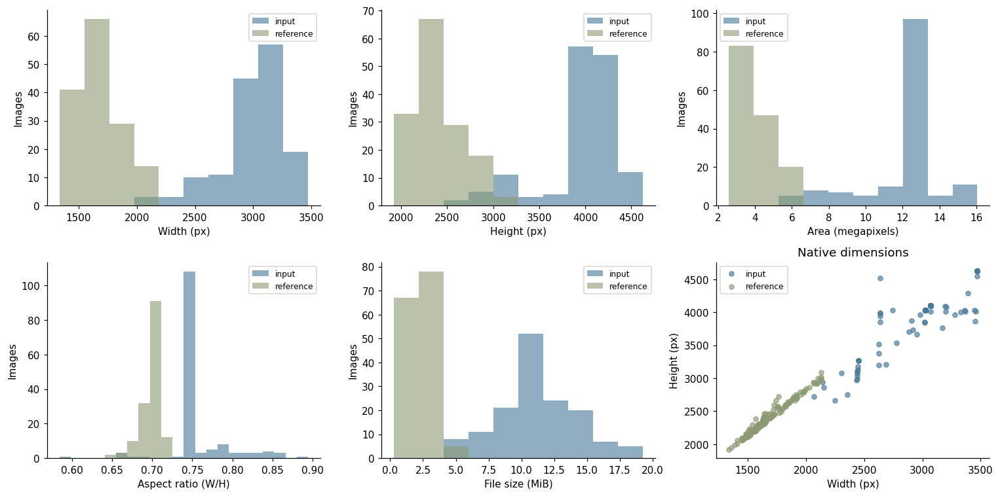

In [5]:
DIMENSION_METRICS = ['width', 'height', 'megapixels', 'aspect_w_h', 'file_mib']
PHOTO_METRICS = ['brightness_mean', 'contrast_std', 'contrast_p95_p05',
                 'red_mean', 'green_mean', 'blue_mean', 'saturation_mean',
                 'dark_fraction', 'bright_fraction', 'gray_entropy_bits']
dimension_summary = good.groupby('role')[DIMENSION_METRICS].describe(percentiles=[.05, .25, .5, .75, .95])
photometric_summary = good.groupby('role')[PHOTO_METRICS].agg(['min', 'median', 'mean', 'std', 'max'])
display(dimension_summary.round(3))
display(photometric_summary.round(4))
print('10 kích thước phổ biến nhất của từng nhóm:')
resolutions = (good.groupby(['role', 'width', 'height']).size().rename('images').reset_index()
               .sort_values(['role', 'images'], ascending=[True, False]))
display(resolutions.groupby('role', group_keys=False).head(10))
display(good.groupby(['role', 'orientation']).size().rename('images').reset_index())

def finish_figure(fig, filename):
    fig.tight_layout()
    if EXPORT:
        fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plot_specs = [('width', 'Width (px)'), ('height', 'Height (px)'),
              ('megapixels', 'Area (megapixels)'), ('aspect_w_h', 'Aspect ratio (W/H)'),
              ('file_mib', 'File size (MiB)')]
for ax, (metric, label) in zip(axes.flat, plot_specs):
    values = good[metric].dropna().to_numpy()
    bins = np.histogram_bin_edges(values, bins='auto')
    if len(bins) > 61:
        bins = np.linspace(values.min(), values.max(), 61)
    for role, group in good.groupby('role'):
        ax.hist(group[metric], bins=bins, alpha=.6, label=role, color=COLORS[role])
    ax.set(xlabel=label, ylabel='Images')
    ax.legend(fontsize=8)
for role, group in good.groupby('role'):
    axes[1, 2].scatter(group['width'], group['height'], s=22, alpha=.65,
                       label=role, color=COLORS[role])
axes[1, 2].set(xlabel='Width (px)', ylabel='Height (px)', title='Native dimensions')
axes[1, 2].legend(fontsize=8)
finish_figure(fig, '01_dimensions.png')


## 6. Xem mẫu ngẫu nhiên và các cặp input–reference

Cố định seed để lặp lại. Hiển thị đúng tỷ lệ ảnh; không kéo giãn hoặc resize input cho khớp GT.
Quan sát trang cong/gấp, crop thiếu biên, hướng trang, bóng đổ và nội dung có khớp không.


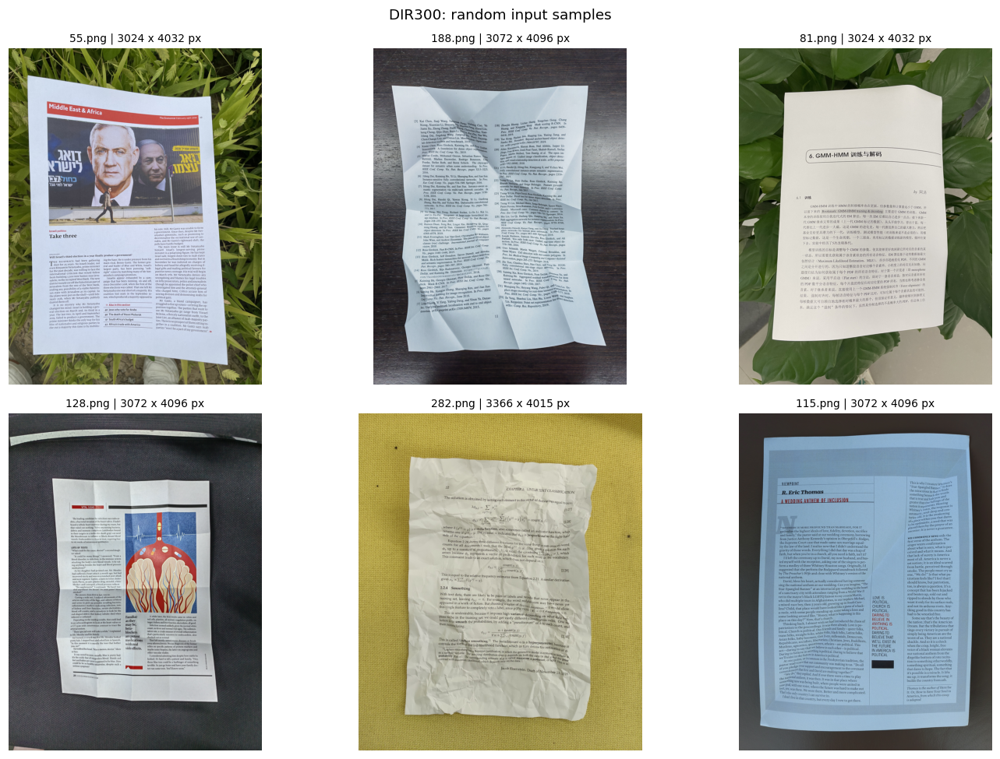

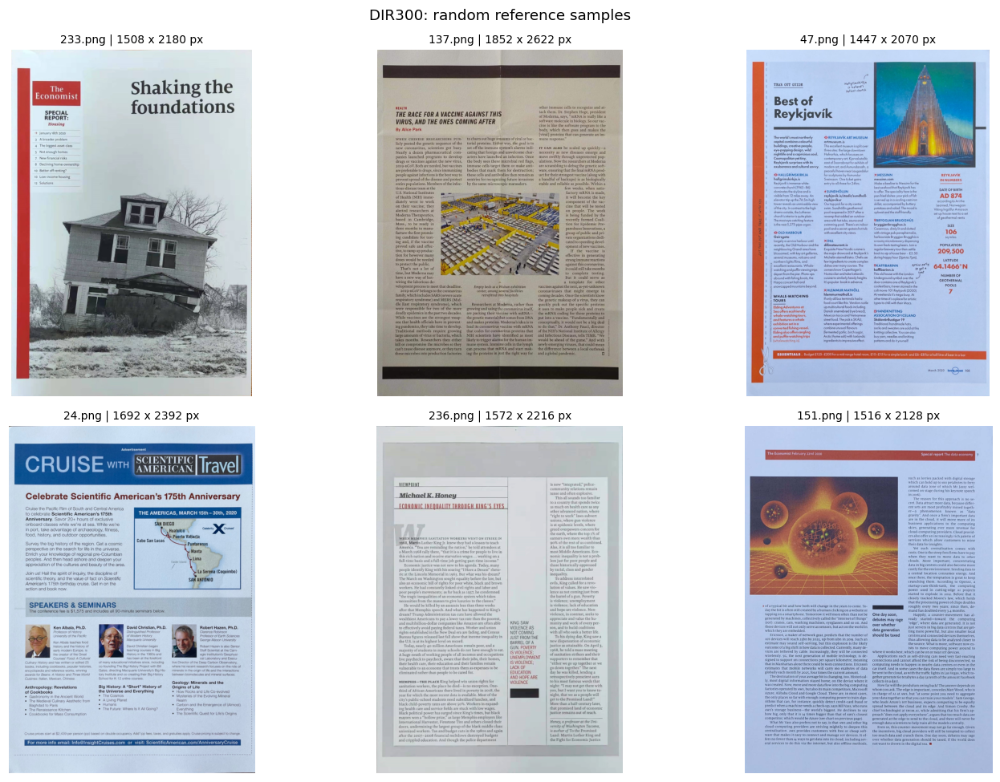

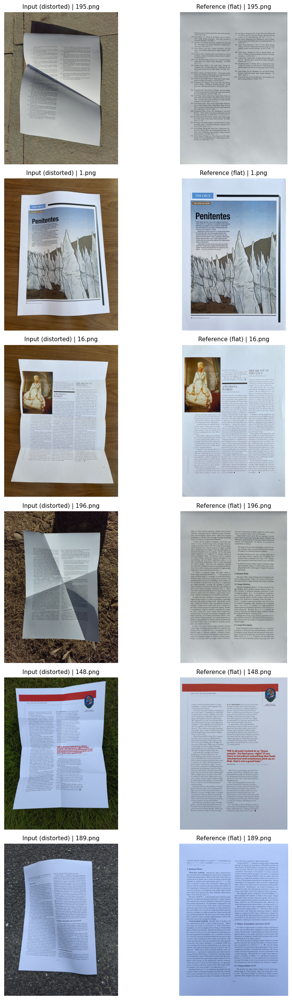

In [6]:
def show_gallery(frame, heading, ncols=3, label_column=None, filename=None):
    if frame.empty:
        print(heading + ': không có ảnh phù hợp.')
        return
    ncols = min(ncols, len(frame))
    nrows = math.ceil(len(frame) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, row in zip(axes.flat, frame.to_dict('records')):
        try:
            thumb = load_thumbnail(row['path'], 900)
            ax.imshow(thumb)
            extra = str(row.get(label_column, '')) if label_column else ''
            title = f"{row['filename']} | {int(row['width'])} x {int(row['height'])} px"
            if extra:
                title = extra + '\n' + title
            ax.set_title(title, fontsize=9, wrap=True)
        except Exception as exc:
            ax.text(.5, .5, f'Cannot display\n{type(exc).__name__}', ha='center', transform=ax.transAxes)
    fig.suptitle(heading, fontsize=12)
    finish_figure(fig, filename or 'gallery.png')

for role, group in good.groupby('role'):
    sample = group.sample(min(SAMPLE_COUNT, len(group)), random_state=SEED)
    show_gallery(sample, f'{DATASET_NAME}: random {role} samples', filename=f'02_samples_{role}.png')

sample_pairs = pairs[pairs['readable_pair']].sample(
    min(SAMPLE_COUNT, int(pairs['readable_pair'].sum())), random_state=SEED)
if len(sample_pairs):
    fig, axes = plt.subplots(len(sample_pairs), 2, figsize=(10, 4 * len(sample_pairs)), squeeze=False)
    for row_axes, pair in zip(axes, sample_pairs.to_dict('records')):
        for ax, key, label in zip(row_axes, ['input_path', 'reference_path'], ['Input (distorted)', 'Reference (flat)']):
            ax.imshow(load_thumbnail(pair[key], 1000))
            ax.set_title(f"{label} | {Path(pair[key]).name}", fontsize=10)
            ax.axis('off')
    finish_figure(fig, '03_matched_pairs.png')
else:
    print('Chưa có cặp đọc được để hiển thị. Xem pair audit ở phần 3.')


## 7. Ảnh nhỏ/lớn nhất theo W, H, diện tích và dung lượng

Bảng giữ **tất cả ảnh đồng hạng**; gallery chọn một ảnh đại diện mỗi tiêu chí và gộp nhãn
nếu cùng ảnh đạt nhiều cực trị. Có kiểm tra riêng trường hợp đồng thời min/max W và H.
**Min diện tích W×H không có nghĩa là vừa min W vừa min H.**


,role,criterion,tie_count,relative_path,filename,width,height,pixels,file_mib
0,input,min_width,1,data/DIR300/dist/297.png,297.png,2070,2724,5638680,5.449003
1,input,max_width,11,data/DIR300/dist/201.png,201.png,3472,4624,16054528,17.909898
2,input,max_width,11,data/DIR300/dist/210.png,210.png,3472,4624,16054528,16.651759
3,input,max_width,11,data/DIR300/dist/214.png,214.png,3472,4624,16054528,18.136668
4,input,max_width,11,data/DIR300/dist/216.png,216.png,3472,4552,15804544,9.758317
5,input,max_width,11,data/DIR300/dist/220.png,220.png,3472,4624,16054528,15.379466
6,input,max_width,11,data/DIR300/dist/224.png,224.png,3472,4624,16054528,16.496547
7,input,max_width,11,data/DIR300/dist/225.png,225.png,3472,4624,16054528,17.258095
8,input,max_width,11,data/DIR300/dist/228.png,228.png,3472,4624,16054528,14.771064
9,input,max_width,11,data/DIR300/dist/276.png,276.png,3472,4624,16054528,15.583803


input: min width và min height đồng thời: 0 ảnh
input: max width và max height đồng thời: 10 ảnh


,relative_path,width,height,megapixels
61,data/DIR300/dist/201.png,3472,4624,16.054528
65,data/DIR300/dist/210.png,3472,4624,16.054528
67,data/DIR300/dist/214.png,3472,4624,16.054528
70,data/DIR300/dist/220.png,3472,4624,16.054528
72,data/DIR300/dist/224.png,3472,4624,16.054528
73,data/DIR300/dist/225.png,3472,4624,16.054528
74,data/DIR300/dist/228.png,3472,4624,16.054528
100,data/DIR300/dist/276.png,3472,4624,16.054528
101,data/DIR300/dist/278.png,3472,4624,16.054528
103,data/DIR300/dist/281.png,3472,4624,16.054528


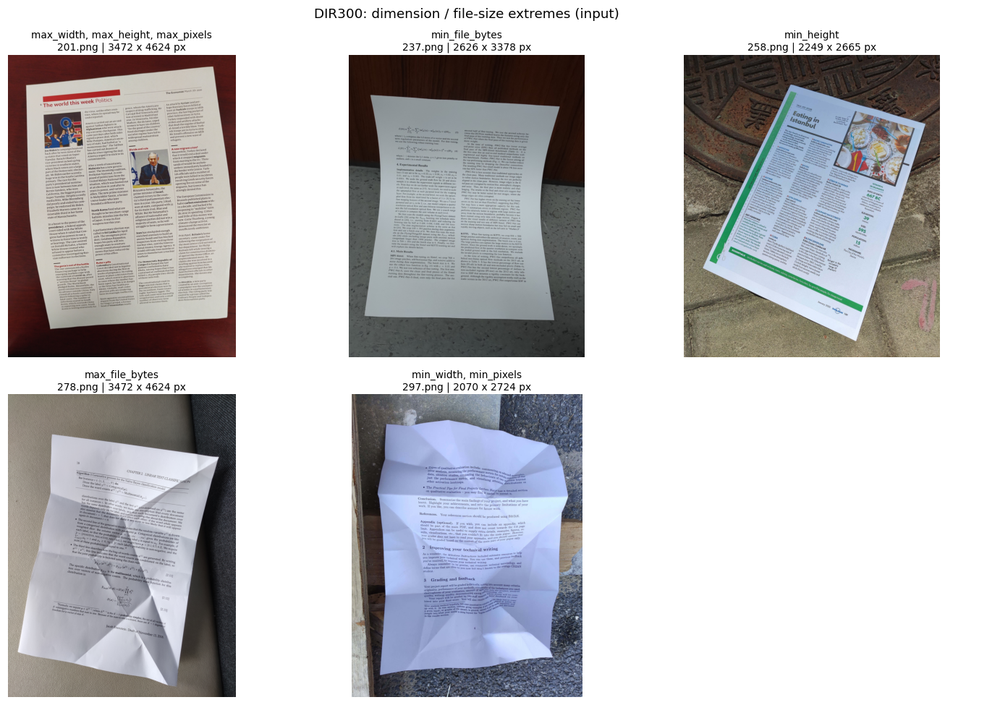

reference: min width và min height đồng thời: 1 ảnh


,relative_path,width,height,megapixels
240,data/DIR300/gt/263.png,1336,1922,2.567792


reference: max width và max height đồng thời: 0 ảnh


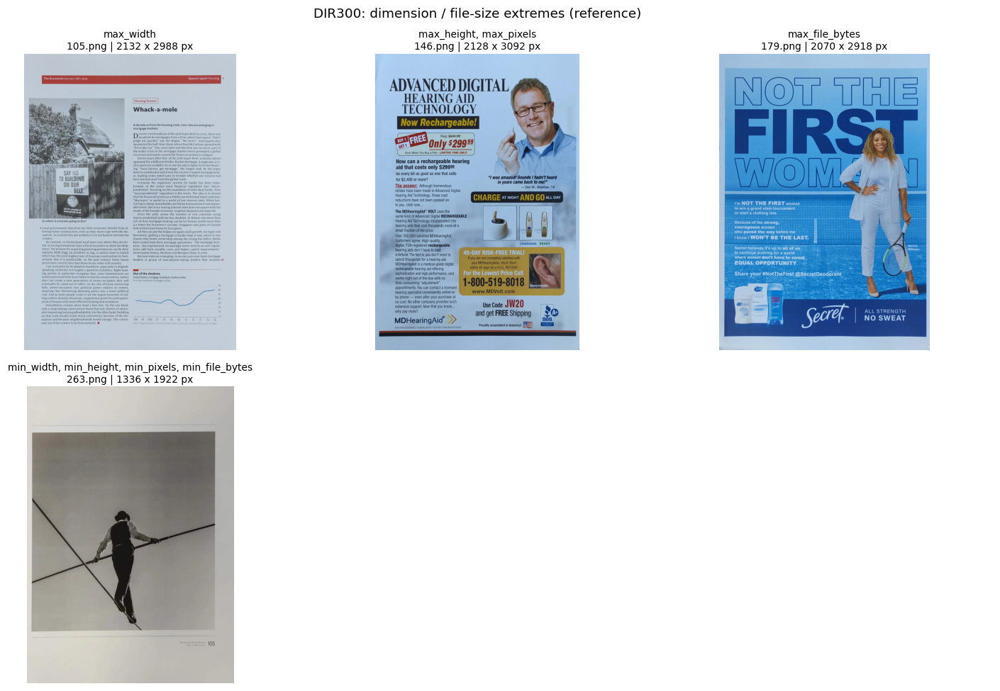

In [7]:
extreme_rows = []
for role, group in good.groupby('role'):
    # Lưu tất cả ảnh đồng hạng, không chỉ idxmin/idxmax đầu tiên.
    for metric in ['width', 'height', 'pixels', 'file_bytes']:
        for direction, value in [('min', group[metric].min()), ('max', group[metric].max())]:
            tied = group[group[metric].eq(value)]
            for _, row in tied.iterrows():
                extreme_rows.append({'role': role, 'criterion': f'{direction}_{metric}',
                                     'tie_count': len(tied), 'path': row['path'],
                                     'relative_path': row['relative_path'], 'filename': row['filename'],
                                     'width': row['width'], 'height': row['height'],
                                     'pixels': row['pixels'], 'file_mib': row['file_mib']})
extremes = pd.DataFrame(extreme_rows)
display(extremes.drop(columns='path'))

for role, group in good.groupby('role'):
    for direction, reducer in [('min', 'min'), ('max', 'max')]:
        both = group[group['width'].eq(getattr(group['width'], reducer)()) &
                     group['height'].eq(getattr(group['height'], reducer)())]
        print(f'{role}: {direction} width và {direction} height đồng thời: {len(both)} ảnh')
        if len(both):
            display(both[['relative_path', 'width', 'height', 'megapixels']])
    chosen = extremes[extremes['role'].eq(role)].drop_duplicates('criterion')
    labels = chosen.groupby('path')['criterion'].agg(lambda x: ', '.join(x))
    gallery = group[group['path'].isin(labels.index)].copy()
    gallery['extreme_label'] = gallery['path'].map(labels)
    show_gallery(gallery, f'{DATASET_NAME}: dimension / file-size extremes ({role})',
                 label_column='extreme_label', filename=f'04_size_extremes_{role}.png')


## 8. Màu sắc, độ sáng và độ tương phản

Histogram đầu tiên là phân bố **giá trị trung bình/độ lệch chuẩn theo ảnh**.
Biểu đồ RGB dùng trung bình đều giữa các ảnh, không để ảnh nhiều pixel chiếm ưu thế.
Histogram pixel RGB/grayscale ở cuối chỉ thuộc **một ảnh mẫu**, không đại diện toàn dataset.


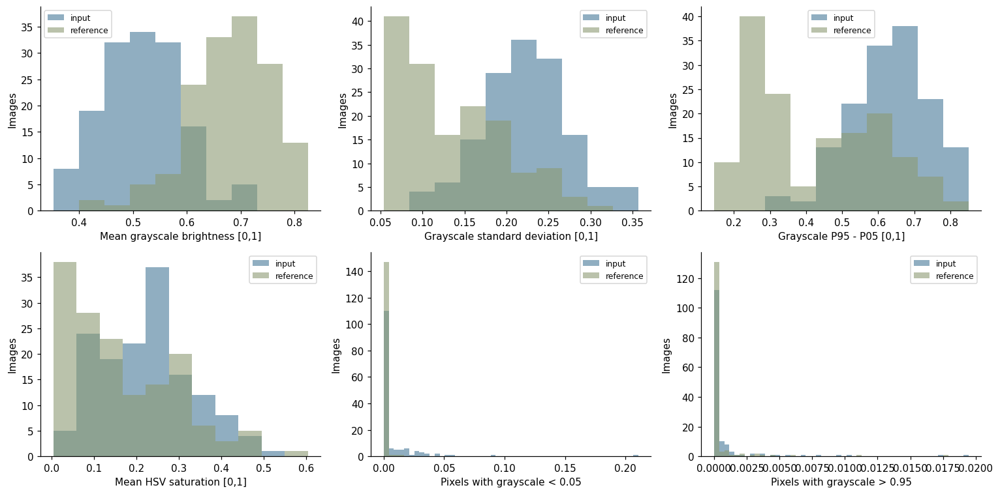

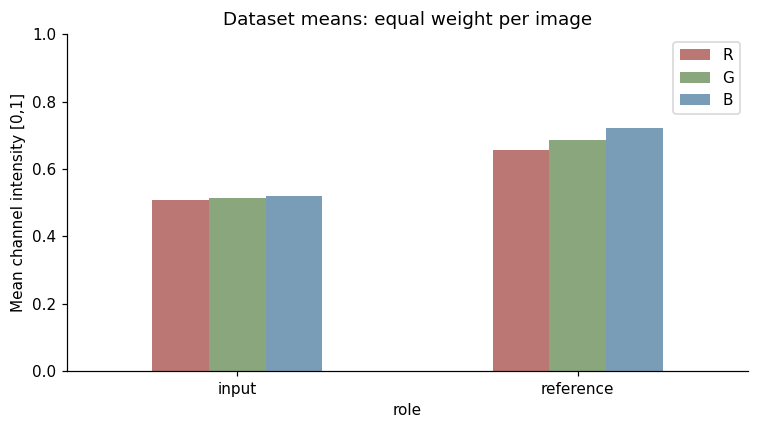

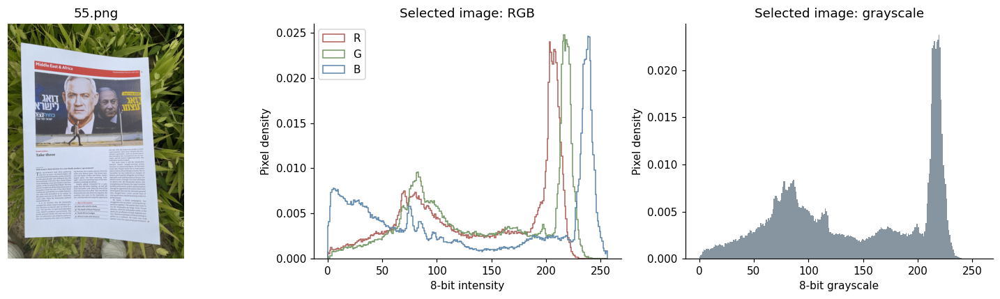

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
photo_plots = [('brightness_mean', 'Mean grayscale brightness [0,1]'),
              ('contrast_std', 'Grayscale standard deviation [0,1]'),
              ('contrast_p95_p05', 'Grayscale P95 - P05 [0,1]'),
              ('saturation_mean', 'Mean HSV saturation [0,1]'),
              ('dark_fraction', 'Pixels with grayscale < 0.05'),
              ('bright_fraction', 'Pixels with grayscale > 0.95')]
for ax, (metric, label) in zip(axes.flat, photo_plots):
    bins = np.histogram_bin_edges(good[metric], bins='auto')
    if len(bins) > 51:
        bins = np.linspace(good[metric].min(), good[metric].max(), 51)
    for role, group in good.groupby('role'):
        ax.hist(group[metric], bins=bins, alpha=.6, label=role, color=COLORS[role])
    ax.set(xlabel=label, ylabel='Images')
    ax.legend(fontsize=8)
finish_figure(fig, '05_photometric_distributions.png')

rgb_means = good.groupby('role')[['red_mean', 'green_mean', 'blue_mean']].mean()
rgb_means.columns = ['R', 'G', 'B']
ax = rgb_means.plot.bar(color=['#BA7773', '#89A67D', '#7A9DB7'], rot=0, figsize=(7, 4))
ax.set(ylabel='Mean channel intensity [0,1]', title='Dataset means: equal weight per image', ylim=(0, 1))
finish_figure(ax.figure, '06_mean_rgb.png')

# Histogram pixel-level của một ảnh input cố định; không giả vờ đây là histogram toàn dataset.
input_good = good[good['role'].eq('input')]
if len(input_good):
    chosen = input_good.sample(1, random_state=SEED).iloc[0]
    thumb = load_thumbnail(chosen['path'])
    arr = np.asarray(thumb)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(thumb)
    axes[0].axis('off')
    axes[0].set_title(chosen['filename'])
    for channel, color, label in [(0, '#B25E59', 'R'), (1, '#739866', 'G'), (2, '#5B85AD', 'B')]:
        axes[1].hist(arr[:, :, channel].ravel(), bins=np.arange(257), density=True,
                     histtype='step', color=color, label=label)
    axes[1].set(xlabel='8-bit intensity', ylabel='Pixel density', title='Selected image: RGB')
    axes[1].legend()
    axes[2].hist(np.asarray(thumb.convert('L')).ravel(), bins=np.arange(257), density=True, color='#8795A1')
    axes[2].set(xlabel='8-bit grayscale', ylabel='Pixel density', title='Selected image: grayscale')
    finish_figure(fig, '07_selected_image_histograms.png')


## 9. Xem ảnh cực trị về ánh sáng, tương phản và màu

Xem ảnh để giải thích số đo. Tương phản thấp có thể do bóng/mờ hoặc nội dung ít chữ;
saturation thấp cũng có thể chỉ là tài liệu đen trắng. Các cực trị không phải nhãn lỗi tự động.
Bảng lưu đủ các ảnh đồng hạng; gallery lấy một ảnh đại diện mỗi tiêu chí.


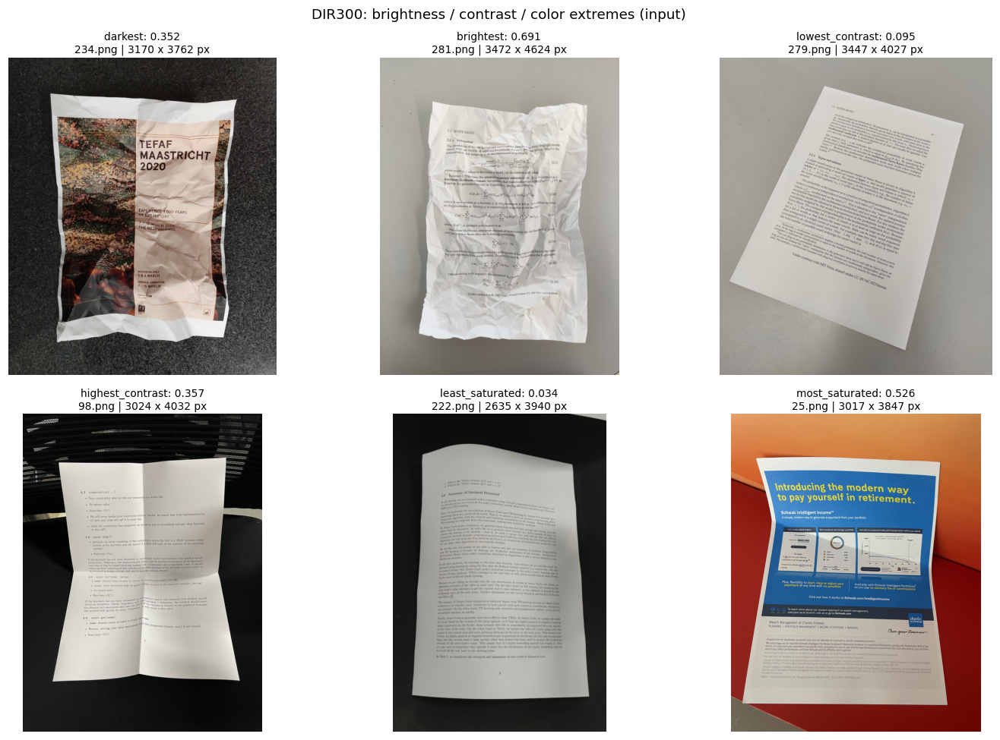

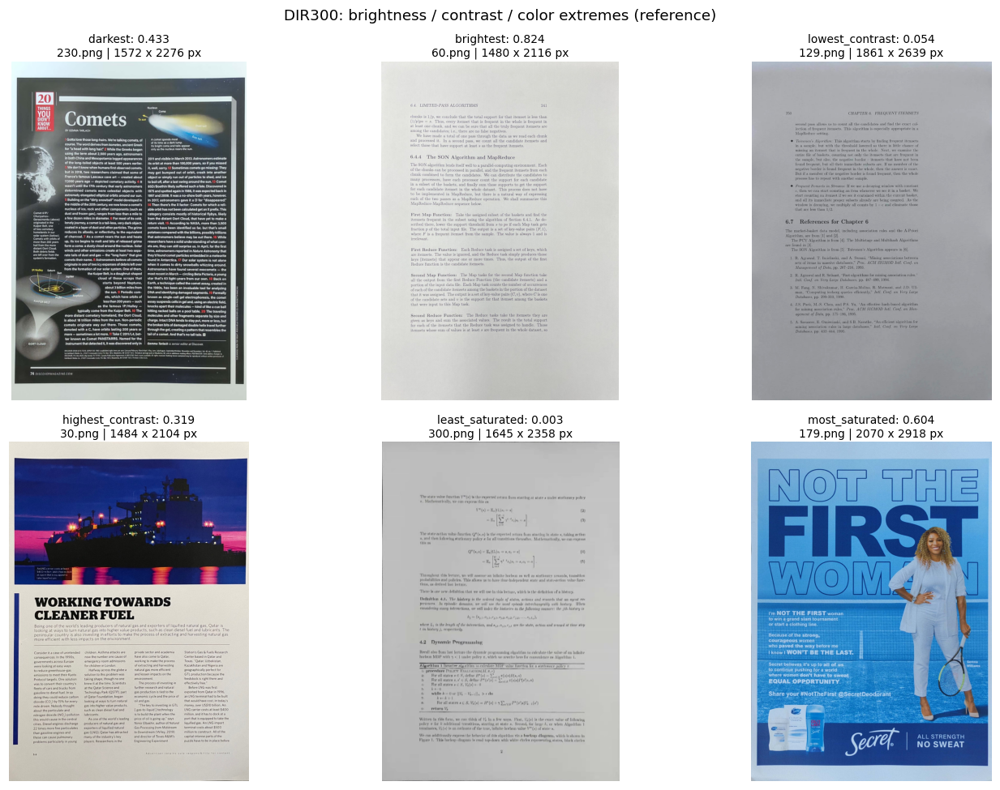

,role,criterion,metric,value,relative_path,tie_count
0,input,darkest,brightness_mean,0.352097,data/DIR300/dist/234.png,1
1,input,brightest,brightness_mean,0.690815,data/DIR300/dist/281.png,1
2,input,lowest_contrast,contrast_std,0.095257,data/DIR300/dist/279.png,1
3,input,highest_contrast,contrast_std,0.356854,data/DIR300/dist/98.png,1
4,input,least_saturated,saturation_mean,0.033691,data/DIR300/dist/222.png,1
5,input,most_saturated,saturation_mean,0.526258,data/DIR300/dist/25.png,1
6,reference,darkest,brightness_mean,0.432769,data/DIR300/gt/230.png,1
7,reference,brightest,brightness_mean,0.824407,data/DIR300/gt/60.png,1
8,reference,lowest_contrast,contrast_std,0.053830,data/DIR300/gt/129.png,1
9,reference,highest_contrast,contrast_std,0.319304,data/DIR300/gt/30.png,1


In [9]:
photo_extreme_rows = []
for role, group in good.groupby('role'):
    selectors = [('darkest', 'brightness_mean', 'min'), ('brightest', 'brightness_mean', 'max'),
                 ('lowest_contrast', 'contrast_std', 'min'), ('highest_contrast', 'contrast_std', 'max'),
                 ('least_saturated', 'saturation_mean', 'min'), ('most_saturated', 'saturation_mean', 'max')]
    picked = []
    for label, metric, direction in selectors:
        extreme_value = getattr(group[metric], direction)()
        candidates = group[group[metric].eq(extreme_value)]
        for _, candidate in candidates.iterrows():
            photo_extreme_rows.append({'role': role, 'criterion': label, 'metric': metric,
                                       'value': extreme_value, 'relative_path': candidate['relative_path'],
                                       'tie_count': len(candidates)})
        row = candidates.iloc[0].copy()
        row['photo_label'] = f'{label}: {extreme_value:.3f}'
        picked.append(row)
    show_gallery(pd.DataFrame(picked), f'{DATASET_NAME}: brightness / contrast / color extremes ({role})',
                 label_column='photo_label', filename=f'08_photo_extremes_{role}.png')
photo_extremes = pd.DataFrame(photo_extreme_rows)
display(photo_extremes)


## 10. Kích thước input so với reference

Kiểm tra tỷ lệ diện tích, aspect ratio và các cặp cùng W/H. Input và reference khác kích thước
không mặc nhiên là lỗi. Không tính SSIM/LD bằng cách resize thẳng hai ảnh chưa căn chỉnh:
đó không phải protocol đánh giá unwarping hợp lệ.


,document_id,view_id,input_relative_path,reference_relative_path,input_width,input_height,reference_width,reference_height,input_reference_area_ratio,input_reference_aspect_ratio,same_dimensions
0,1,,data/DIR300/dist/1.png,data/DIR300/gt/1.png,3024,4032,1756,2568,2.703851,1.096811,False
1,102,,data/DIR300/dist/102.png,data/DIR300/gt/102.png,3072,4096,1976,2800,2.274239,1.062753,False
2,106,,data/DIR300/dist/106.png,data/DIR300/gt/106.png,3072,4096,2080,2928,2.066078,1.055769,False
3,107,,data/DIR300/dist/107.png,data/DIR300/gt/107.png,3072,4096,2088,2920,2.063801,1.048851,False
4,110,,data/DIR300/dist/110.png,data/DIR300/gt/110.png,3072,4096,2116,2976,1.998171,1.054820,False
5,113,,data/DIR300/dist/113.png,data/DIR300/gt/113.png,3072,4096,1800,2532,2.760864,1.055000,False
6,114,,data/DIR300/dist/114.png,data/DIR300/gt/114.png,3072,4096,2104,3004,1.990836,1.070817,False
7,115,,data/DIR300/dist/115.png,data/DIR300/gt/115.png,3072,4096,2096,2916,2.058744,1.043416,False
8,120,,data/DIR300/dist/120.png,data/DIR300/gt/120.png,3072,4096,1827,2607,2.641810,1.070197,False
9,123,,data/DIR300/dist/123.png,data/DIR300/gt/123.png,3072,4096,2028,2856,2.172476,1.056213,False


,input_reference_area_ratio,input_reference_aspect_ratio
count,83.000,83.000
mean,3.013,1.086
std,0.779,0.058
min,1.730,0.837
25%,2.480,1.061
50%,2.965,1.070
75%,3.430,1.104
max,5.674,1.268


Cặp có cùng W,H: 0 / 83


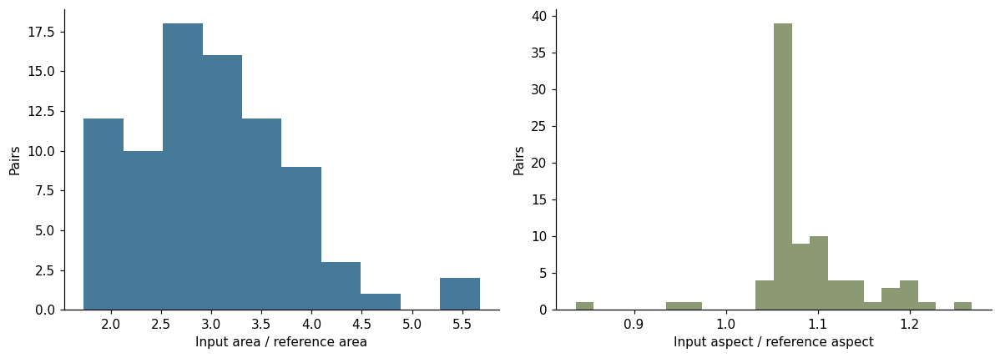

In [10]:
lookup = good.set_index('path')
pair_size_records = []
for pair in pairs[pairs['readable_pair']].to_dict('records'):
    src, ref = lookup.loc[pair['input_path']], lookup.loc[pair['reference_path']]
    pair_size_records.append({'document_id': pair['document_id'], 'view_id': pair['view_id'],
                              'input_relative_path': pair['input_relative_path'],
                              'reference_relative_path': pair['reference_relative_path'],
                              'input_width': src['width'], 'input_height': src['height'],
                              'reference_width': ref['width'], 'reference_height': ref['height'],
                              'input_reference_area_ratio': src['pixels'] / ref['pixels'],
                              'input_reference_aspect_ratio': src['aspect_w_h'] / ref['aspect_w_h'],
                              'same_dimensions': src['width'] == ref['width'] and src['height'] == ref['height']})
pair_sizes = pd.DataFrame(pair_size_records)
if len(pair_sizes):
    display(pair_sizes.head(15))
    display(pair_sizes[['input_reference_area_ratio', 'input_reference_aspect_ratio']].describe().round(3))
    print('Cặp có cùng W,H:', int(pair_sizes['same_dimensions'].sum()), '/', len(pair_sizes))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(pair_sizes['input_reference_area_ratio'], bins='auto', color=COLORS['input'])
    axes[0].set(xlabel='Input area / reference area', ylabel='Pairs')
    axes[1].hist(pair_sizes['input_reference_aspect_ratio'], bins='auto', color=COLORS['reference'])
    axes[1].set(xlabel='Input aspect / reference aspect', ylabel='Pairs')
    finish_figure(fig, '09_pair_dimension_ratios.png')
else:
    print('Chưa có cặp đọc được; bỏ qua so sánh kích thước cặp.')


## 11. Xuất kết quả và ghi nhận kết luận

`EXPORT=True` lưu bảng CSV, hình PNG và cấu hình chạy vào `reports/eda/<dataset>/`.
Các đường dẫn trong CSV tương đối với repo để dễ chia sẻ. Thư mục này đã được `.gitignore` bỏ qua.

Trước khi chốt thí nghiệm, ghi lại: số ảnh/cặp thực có; ID thiếu/lỗi; miền W/H và megapixels;
độ đa dạng màu/ánh sáng; ví dụ khó; kế hoạch resize/padding giữ tỷ lệ; những khác biệt giữa input
và reference cần được xử lý theo protocol benchmark. Nếu chia tập, chia theo document ID.
Giữ benchmark làm tập test; không chọn tham số từ kết quả test cuối.

**Trước khi commit notebook:** lưu bản có output ở máy nếu cần, rồi Clear All Outputs và Save
bản đem commit. `.gitignore` không thể loại ảnh nhúng bên trong một file `.ipynb` đã được theo dõi.


In [11]:
if EXPORT:
    tables = {
        'inventory.csv': inventory.drop(columns='path'),
        'image_statistics.csv': stats.drop(columns='path'),
        'read_errors.csv': errors.drop(columns='path'),
        'pair_audit.csv': pairs.drop(columns=['input_path', 'reference_path']),
        'unrecognized_names.csv': bad_names.drop(columns='path'),
        'duplicate_ids.csv': duplicate_names.drop(columns='path'),
        'references_without_inputs.csv': unreferenced.drop(columns='path'),
        'size_extremes.csv': extremes.drop(columns='path'),
        'photometric_extremes.csv': photo_extremes,
        'pair_dimensions.csv': pair_sizes,
        'count_audit.csv': count_table,
    }
    for name, table in tables.items():
        table.to_csv(OUTPUT_DIR / name, index=False, encoding='utf-8-sig')
    dimension_summary.to_csv(OUTPUT_DIR / 'dimension_summary.csv', encoding='utf-8-sig')
    photometric_summary.to_csv(OUTPUT_DIR / 'photometric_summary.csv', encoding='utf-8-sig')
    metadata = {'dataset': DATASET_NAME, 'seed': SEED, 'analysis_max_side': ANALYSIS_MAX_SIDE,
                'expected_counts': EXPECTED_COUNTS, 'found_counts': counts.to_dict(),
                'readable_images': len(good), 'failed_images': len(errors),
                'readable_pairs': int(pairs['readable_pair'].sum()),
                'brightness_definition': 'Mean Pillow L / 255 on EXIF-corrected RGB thumbnail, alpha over white',
                'contrast_definition': 'Population std and P95-P05 of the same grayscale thumbnail',
                'averaging': 'Dataset means give equal weight to each image; reference counted once per file',
                'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                'pillow': PIL.__version__, 'matplotlib': matplotlib.__version__}
    (OUTPUT_DIR / 'run_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    print('Đã xuất CSV / PNG / metadata tới:', OUTPUT_DIR)
else:
    print('EXPORT=False: chỉ hiển thị trong notebook.')

print('Tóm tắt dữ liệu THỰC SỰ có trên máy:')
print(f'- {len(inputs)} input; {len(references)} reference; {len(errors)} ảnh lỗi.')
print(f'- {int(pairs["readable_pair"].sum())}/{len(pairs)} input có cặp reference đọc được.')
if len(duplicate_names) or len(bad_names) or len(errors) or (len(pairs) and not pairs['readable_pair'].all()):
    print('- Cần giải quyết vấn đề trong các bảng audit trước khi đánh giá phương pháp.')


Đã xuất CSV / PNG / metadata tới: D:\HCMUT\HK261\CV\ImageProcessing_and_ComputerVision_CC01\reports\eda\dir300
Tóm tắt dữ liệu THỰC SỰ có trên máy:
- 148 input; 150 reference; 0 ảnh lỗi.
- 83/148 input có cặp reference đọc được.
- Cần giải quyết vấn đề trong các bảng audit trước khi đánh giá phương pháp.
